<a href="https://colab.research.google.com/github/PankajRao0004/DL-TCN-Project/blob/main/TCN_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
from pathlib import Path

# Connect Google Drive to this Colab session
drive.mount('/content/drive')

# Locate our project folder
PROJECT_DIR = Path('/content/drive/MyDrive/DL_TCN_Project')

# Confirm that the folder exists
assert PROJECT_DIR.is_dir(), f"Project folder not found: {PROJECT_DIR}"

# Test writing a file to Drive
test_file = PROJECT_DIR / "drive_test.txt"
test_file.write_text("Drive backup test successful.", encoding="utf-8")

# Test reading the same file back
content = test_file.read_text(encoding="utf-8")
assert content == "Drive backup test successful."

# Remove the temporary test file
test_file.unlink()

print("SUCCESS: Google Drive read/write verified.")
print(f"Project folder: {PROJECT_DIR}")

Mounted at /content/drive
SUCCESS: Google Drive read/write verified.
Project folder: /content/drive/MyDrive/DL_TCN_Project


In [4]:
from pathlib import Path

# Main project folder in Google Drive
PROJECT_DIR = Path("/content/drive/MyDrive/DL_TCN_Project")

# Folders for saving models, results and the report
folders = [
    PROJECT_DIR / "checkpoints",
    PROJECT_DIR / "results",
    PROJECT_DIR / "results" / "plots",
    PROJECT_DIR / "report",
]

# Create folders without deleting any existing work
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")

for folder in folders:
    print(folder.relative_to(PROJECT_DIR))

Project folders created successfully!
checkpoints
results
results/plots
report


In [5]:
# Step 14: Load and test our own TCN implementation

from pathlib import Path
import subprocess
import sys
import torch

REPO_URL = "https://github.com/PankajRao0004/DL-TCN-Project.git"
REPO_DIR = Path("/content/DL-TCN-Project")

# Retrieve the latest committed code, without duplicating the repository.
if REPO_DIR.exists():
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull", "--ff-only"],
        check=True
    )
else:
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )

assert (REPO_DIR / "tcn.py").is_file(), (
    "tcn.py was not found in GitHub. Check that the file was pushed."
)

# Import the exact implementation from our repository.
sys.path.insert(0, str(REPO_DIR))
from tcn import TemporalConvNet

# Use a small model: this is a correctness test, not training.
torch.manual_seed(42)

model = TemporalConvNet(
    input_channels=2,
    channels=[8, 16, 16],
    kernel_size=3,
    dropout=0.1,
)
model.eval()

# Test 1: Output shape and residual connections.
x = torch.randn(4, 2, 64)

with torch.no_grad():
    y = model(x)

assert y.shape == (4, 16, 64), f"Unexpected shape: {y.shape}"
print("PASS: Output shape and residual connections.")

# Test 2: Changing future inputs must not change past outputs.
time_idx = 30
x_changed = x.clone()
x_changed[:, :, time_idx + 1:] += 10.0

with torch.no_grad():
    y_original = model(x)
    y_changed = model(x_changed)

assert torch.allclose(
    y_original[:, :, :time_idx + 1],
    y_changed[:, :, :time_idx + 1],
    atol=1e-6,
    rtol=0.0,
), "Causality test failed: future inputs changed past outputs."

print("PASS: Causality — future inputs do not affect past outputs.")

# Test 3: Verify the receptive field calculation.
expected_rf = 1 + 2 * (3 - 1) * (2**3 - 1)

assert model.receptive_field == expected_rf, (
    f"Expected receptive field {expected_rf}, "
    f"got {model.receptive_field}"
)

print(f"PASS: Receptive field = {model.receptive_field} time steps.")
print("\nAll TCN core tests passed.")

PASS: Output shape and residual connections.
PASS: Causality — future inputs do not affect past outputs.
PASS: Receptive field = 29 time steps.

All TCN core tests passed.


In [6]:
# Adding Problem: data generation and sanity checks

import torch

torch.manual_seed(42)


def generate_adding_data(num_samples, seq_len=100):
    """
    Each sequence has two channels:
    1. Random values between 0 and 1.
    2. A marker channel with exactly two marked positions.

    The target is the sum of the two marked values.
    """
    values = torch.rand(num_samples, seq_len)

    # Select two distinct positions in each sequence.
    positions = torch.rand(num_samples, seq_len).argsort(dim=1)[:, :2]

    markers = torch.zeros_like(values)
    markers.scatter_(1, positions, 1.0)

    # Add channel dimension: [samples, 2, sequence_length].
    inputs = torch.stack([values, markers], dim=1)

    # One target value per sequence.
    targets = (values * markers).sum(dim=1, keepdim=True)

    return inputs, targets


# Generate a small dataset for verification.
x_test, y_test = generate_adding_data(num_samples=2048, seq_len=100)

# Verify tensor shapes.
assert x_test.shape == (2048, 2, 100)
assert y_test.shape == (2048, 1)

# Verify that every sequence has exactly two marked positions.
assert torch.all(x_test[:, 1, :].sum(dim=1) == 2)

# Verify the targets match the marked values.
calculated_targets = (
    x_test[:, 0, :] * x_test[:, 1, :]
).sum(dim=1, keepdim=True)

assert torch.allclose(y_test, calculated_targets)

# A constant prediction of 1 is our trivial baseline.
baseline_mse = torch.mean((y_test - 1.0) ** 2).item()

print("PASS: Input shape:", tuple(x_test.shape))
print("PASS: Target shape:", tuple(y_test.shape))
print("PASS: Exactly two markers per sequence.")
print("PASS: Targets match the marked values.")
print(f"Constant-prediction baseline MSE: {baseline_mse:.4f}")

PASS: Input shape: (2048, 2, 100)
PASS: Target shape: (2048, 1)
PASS: Exactly two markers per sequence.
PASS: Targets match the marked values.
Constant-prediction baseline MSE: 0.1682


In [8]:
# Step 16: Adding Problem benchmark with automatic recovery

import csv
import subprocess
import sys
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F

# --------------------------------------------------
# 1. Set up Drive and load our TCN implementation
# --------------------------------------------------

from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DL_TCN_Project")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

REPO_URL = "https://github.com/PankajRao0004/DL-TCN-Project.git"
REPO_DIR = Path("/content/DL-TCN-Project")

if (REPO_DIR / "tcn.py").exists():
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull", "--ff-only"],
        check=True
    )
else:
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )

sys.path.insert(0, str(REPO_DIR))
from tcn import TemporalConvNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

# --------------------------------------------------
# 2. Generate fixed, reproducible data splits
# --------------------------------------------------

SEQ_LEN = 100
TRAIN_SIZE = 4096
VAL_SIZE = 1024
TEST_SIZE = 2048
BATCH_SIZE = 128
EPOCHS = 20


def make_adding_data(num_samples, seed):
    """Generate sequences and the sum of their two marked values."""

    generator = torch.Generator().manual_seed(seed)

    values = torch.rand(
        num_samples, SEQ_LEN, generator=generator
    )

    # Choose two distinct random time positions.
    random_scores = torch.rand(
        num_samples, SEQ_LEN, generator=generator
    )
    positions = random_scores.argsort(dim=1)[:, :2]

    markers = torch.zeros_like(values)
    markers.scatter_(1, positions, 1.0)

    # Shape: [samples, 2 channels, time steps].
    inputs = torch.stack([values, markers], dim=1)

    # Target: sum the values at the marked positions.
    targets = (values * markers).sum(dim=1, keepdim=True)

    return inputs, targets


train_x, train_y = make_adding_data(TRAIN_SIZE, seed=101)
val_x, val_y = make_adding_data(VAL_SIZE, seed=202)
test_x, test_y = make_adding_data(TEST_SIZE, seed=303)

# Move the small datasets to the selected device once.
train_x, train_y = train_x.to(device), train_y.to(device)
val_x, val_y = val_x.to(device), val_y.to(device)
test_x, test_y = test_x.to(device), test_y.to(device)

assert torch.all(train_x[:, 1, :].sum(dim=1) == 2)
assert train_x.shape == (TRAIN_SIZE, 2, SEQ_LEN)

baseline_test_mse = ((test_y - 1.0) ** 2).mean().item()
print(f"Constant-prediction test baseline: {baseline_test_mse:.4f}")

# --------------------------------------------------
# 3. Task-specific TCN, LSTM and GRU models
# --------------------------------------------------

class AddingTCN(nn.Module):
    def __init__(self):
        super().__init__()

        # RF = 1 + 2*(kernel_size-1)*(2**levels - 1)
        # With 5 levels and kernel 3, RF = 125.
        # This covers our entire 100-step input sequence.
        self.backbone = TemporalConvNet(
            input_channels=2,
            channels=[16, 16, 16, 16, 16],
            kernel_size=3,
            dropout=0.1,
        )
        self.readout = nn.Linear(16, 1)

    def forward(self, x):
        features = self.backbone(x)
        # Predict the sum from the final time step.
        return self.readout(features[:, :, -1])


class AddingRNN(nn.Module):
    def __init__(self, cell_type, hidden_size=48):
        super().__init__()

        if cell_type == "LSTM":
            self.rnn = nn.LSTM(
                input_size=2,
                hidden_size=hidden_size,
                batch_first=True,
            )
        elif cell_type == "GRU":
            self.rnn = nn.GRU(
                input_size=2,
                hidden_size=hidden_size,
                batch_first=True,
            )
        else:
            raise ValueError("cell_type must be LSTM or GRU")

        self.readout = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # Recurrent layers expect [batch, time, features].
        sequence = x.transpose(1, 2)
        outputs, _ = self.rnn(sequence)
        return self.readout(outputs[:, -1, :])


# --------------------------------------------------
# 4. Helpers for durable checkpoints and metrics
# --------------------------------------------------

def atomic_save_torch(path, checkpoint):
    # Write a temporary file first so an interrupted write
    # is less likely to replace the last complete checkpoint.
    temporary_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(path)


def save_csv(path, rows, columns):
    temporary_path = path.with_suffix(path.suffix + ".tmp")

    with temporary_path.open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)

    temporary_path.replace(path)


def evaluate_mse(model, inputs, targets):
    model.eval()

    with torch.no_grad():
        predictions = model(inputs)
        return F.mse_loss(predictions, targets).item()


# --------------------------------------------------
# 5. Training loop: save and resume after each epoch
# --------------------------------------------------

def train_one_model(name, model, config):
    latest_path = CHECKPOINT_DIR / f"adding_{name.lower()}_latest.pt"
    best_path = CHECKPOINT_DIR / f"adding_{name.lower()}_best.pt"
    history_path = RESULTS_DIR / f"adding_{name.lower()}_history.csv"

    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

    start_epoch = 0
    best_val_mse = float("inf")
    history = []

    # Resume this model if a compatible checkpoint exists.
    if latest_path.exists():
        checkpoint = torch.load(
            latest_path, map_location="cpu", weights_only=False
        )

        if (
            checkpoint["model_name"] != name
            or checkpoint["config"] != config
        ):
            raise RuntimeError(
                f"Checkpoint configuration mismatch for {name}. "
                "Do not overwrite the existing checkpoint."
            )

        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])

        start_epoch = checkpoint["epoch"]
        best_val_mse = checkpoint["best_val_mse"]
        history = checkpoint["history"]

        # Restore random-number states for continued training.
        torch.set_rng_state(checkpoint["cpu_rng_state"])

        if (
            device.type == "cuda"
            and checkpoint["cuda_rng_states"] is not None
        ):
            torch.cuda.set_rng_state_all(
                checkpoint["cuda_rng_states"]
            )

        print(f"{name}: resuming after epoch {start_epoch}")

    for epoch in range(start_epoch + 1, EPOCHS + 1):
        model.train()

        # Shuffle training examples for this epoch.
        order = torch.randperm(len(train_x), device=device)
        total_loss = 0.0

        for start in range(0, len(train_x), BATCH_SIZE):
            indices = order[start:start + BATCH_SIZE]

            inputs = train_x[indices]
            targets = train_y[indices]

            optimizer.zero_grad(set_to_none=True)

            predictions = model(inputs)
            loss = F.mse_loss(predictions, targets)

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * len(indices)

        train_mse = total_loss / len(train_x)
        val_mse = evaluate_mse(model, val_x, val_y)

        history.append({
            "epoch": epoch,
            "train_mse": train_mse,
            "val_mse": val_mse,
        })

        improved = val_mse < best_val_mse
        best_val_mse = min(best_val_mse, val_mse)

        # Include everything required to resume training.
        checkpoint = {
            "model_name": name,
            "config": config,
            "epoch": epoch,
            "model_state": {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            "optimizer_state": optimizer.state_dict(),
            "best_val_mse": best_val_mse,
            "history": history,
            "cpu_rng_state": torch.get_rng_state(),
            "cuda_rng_states": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available()
                else None
            ),
        }

        # Keep the best validation model and the latest resumable state.
        if improved:
            atomic_save_torch(best_path, checkpoint)

        atomic_save_torch(latest_path, checkpoint)

        # Persist experiment history after every epoch.
        save_csv(
            history_path,
            history,
            ["epoch", "train_mse", "val_mse"],
        )

        print(
            f"{name} | epoch {epoch:02d}/{EPOCHS} "
            f"| train MSE {train_mse:.5f} "
            f"| val MSE {val_mse:.5f}"
        )

    # Evaluate the best validation checkpoint on the test set.
    best_checkpoint = torch.load(
        best_path, map_location="cpu", weights_only=False
    )
    model.load_state_dict(best_checkpoint["model_state"])

    test_mse = evaluate_mse(model, test_x, test_y)

    return {
        "model": name,
        "parameters": sum(p.numel() for p in model.parameters()),
        "best_epoch": best_checkpoint["epoch"],
        "best_val_mse": best_checkpoint["best_val_mse"],
        "test_mse": test_mse,
        "constant_baseline_test_mse": baseline_test_mse,
        "beats_baseline": test_mse < baseline_test_mse,
    }


# --------------------------------------------------
# 6. Run all required Adding Problem comparisons
# --------------------------------------------------

model_configs = [
    ("TCN", {"channels": [16, 16, 16, 16, 16], "kernel_size": 3}),
    ("LSTM", {"hidden_size": 48}),
    ("GRU", {"hidden_size": 48}),
]

summary_rows = []

summary_path = RESULTS_DIR / "adding_comparison.csv"
summary_columns = [
    "model", "parameters", "best_epoch", "best_val_mse",
    "test_mse", "constant_baseline_test_mse", "beats_baseline",
]

for model_index, (name, config) in enumerate(model_configs):
    # Use consistent initialisation if the experiment is restarted.
    torch.manual_seed(1000 + model_index)

    if name == "TCN":
        model = AddingTCN()
    else:
        model = AddingRNN(name, hidden_size=config["hidden_size"])

    result = train_one_model(name, model, config)
    summary_rows.append(result)

    # Preserve completed model comparisons as we go.
    save_csv(summary_path, summary_rows, summary_columns)

    print(
        f"Finished {name}: test MSE={result['test_mse']:.5f}, "
        f"baseline={baseline_test_mse:.5f}"
    )

print("\nAdding Problem comparison:")
for result in summary_rows:
    print(result)

print(f"\nResults saved to: {summary_path}")
print(f"Model checkpoints saved to: {CHECKPOINT_DIR}")

Training device: cpu
Constant-prediction test baseline: 0.1710
TCN | epoch 01/20 | train MSE 0.46941 | val MSE 0.18665
TCN | epoch 02/20 | train MSE 0.18810 | val MSE 0.16569
TCN | epoch 03/20 | train MSE 0.18671 | val MSE 0.16582
TCN | epoch 04/20 | train MSE 0.18023 | val MSE 0.16290
TCN | epoch 05/20 | train MSE 0.18303 | val MSE 0.17237
TCN | epoch 06/20 | train MSE 0.17507 | val MSE 0.15919
TCN | epoch 07/20 | train MSE 0.16811 | val MSE 0.15598
TCN | epoch 08/20 | train MSE 0.15968 | val MSE 0.14144
TCN | epoch 09/20 | train MSE 0.14376 | val MSE 0.09999
TCN | epoch 10/20 | train MSE 0.09957 | val MSE 0.04838
TCN | epoch 11/20 | train MSE 0.06834 | val MSE 0.02728
TCN | epoch 12/20 | train MSE 0.05367 | val MSE 0.04321
TCN | epoch 13/20 | train MSE 0.04957 | val MSE 0.02073
TCN | epoch 14/20 | train MSE 0.04422 | val MSE 0.02638
TCN | epoch 15/20 | train MSE 0.04301 | val MSE 0.03557
TCN | epoch 16/20 | train MSE 0.04109 | val MSE 0.01981
TCN | epoch 17/20 | train MSE 0.03742 | v

In [9]:
# Step 17: Copy Memory data generation and validation

import torch

def generate_copy_memory_data(num_samples, memory_gap=100, seed=42):
    """
    Create the Copy Memory task.

    The first 10 values contain the information to remember.
    The final 11 input positions contain the delimiter (9).
    The target is zero except for the final 10 positions,
    where the original 10 values must be reproduced.
    """
    sequence_length = memory_gap + 20
    generator = torch.Generator().manual_seed(seed)

    # Input values are initially zero.
    inputs = torch.zeros(num_samples, sequence_length, dtype=torch.long)

    # The initial ten digits are randomly selected from 1 to 8.
    initial_values = torch.randint(
        1, 9, (num_samples, 10), generator=generator
    )
    inputs[:, :10] = initial_values

    # The last eleven input positions are the delimiter.
    inputs[:, -11:] = 9

    # Output is zero except at the last ten positions.
    targets = torch.zeros_like(inputs)
    targets[:, -10:] = initial_values

    return inputs, targets


# Generate a small sample for checking.
copy_x, copy_y = generate_copy_memory_data(
    num_samples=1024,
    memory_gap=100,
    seed=42,
)

# Verify dimensions.
assert copy_x.shape == (1024, 120)
assert copy_y.shape == (1024, 120)

# Verify the initial values and delimiter.
assert torch.all((copy_x[:, :10] >= 1) & (copy_x[:, :10] <= 8))
assert torch.all(copy_x[:, -11:] == 9)

# Verify targets: zeros until the final ten positions.
assert torch.all(copy_y[:, :-10] == 0)
assert torch.equal(copy_y[:, -10:], copy_x[:, :10])

# An all-zero prediction cannot recall any of the target digits.
zero_baseline_accuracy = (
    copy_y[:, -10:] == 0
).float().mean().item()

assert zero_baseline_accuracy == 0.0

print("PASS: Input shape:", tuple(copy_x.shape))
print("PASS: Target shape:", tuple(copy_y.shape))
print("PASS: Initial values and delimiter are correct.")
print("PASS: Final ten targets reproduce the initial values.")
print(f"All-zero baseline accuracy on recall positions: {zero_baseline_accuracy:.1%}")

PASS: Input shape: (1024, 120)
PASS: Target shape: (1024, 120)
PASS: Initial values and delimiter are correct.
PASS: Final ten targets reproduce the initial values.
All-zero baseline accuracy on recall positions: 0.0%


In [10]:
# Step 18: Copy Memory model setup and shape verification

import torch
from torch import nn
from torch.nn import functional as F
from tcn import TemporalConvNet

# Use the existing Colab device if available.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MEMORY_GAP = 100
NUM_CLASSES = 10
SEQUENCE_LENGTH = MEMORY_GAP + 20


class CopyTCN(nn.Module):
    """TCN that predicts one digit at every sequence position."""

    def __init__(self):
        super().__init__()

        self.backbone = TemporalConvNet(
            input_channels=NUM_CLASSES,
            channels=[16, 16, 16, 16, 16],
            kernel_size=3,
            dropout=0.1,
        )
        self.classifier = nn.Conv1d(16, NUM_CLASSES, kernel_size=1)

    def forward(self, tokens):
        # Convert each digit into a one-hot feature vector.
        x = F.one_hot(tokens, num_classes=NUM_CLASSES).float()

        # TCN expects [batch, channels, time].
        x = x.transpose(1, 2)
        return self.classifier(self.backbone(x))


class CopyRNN(nn.Module):
    """LSTM or GRU baseline for sequence copying."""

    def __init__(self, cell_type, hidden_size=64):
        super().__init__()

        recurrent_class = {"LSTM": nn.LSTM, "GRU": nn.GRU}[cell_type]

        self.rnn = recurrent_class(
            input_size=NUM_CLASSES,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.classifier = nn.Linear(hidden_size, NUM_CLASSES)

    def forward(self, tokens):
        # RNN expects [batch, time, features].
        x = F.one_hot(tokens, num_classes=NUM_CLASSES).float()
        outputs, _ = self.rnn(x)
        return self.classifier(outputs)


# Tiny synthetic batch: this is only a forward-pass test.
test_tokens = torch.zeros(4, SEQUENCE_LENGTH, dtype=torch.long).to(device)

models = {
    "TCN": CopyTCN().to(device),
    "LSTM": CopyRNN("LSTM").to(device),
    "GRU": CopyRNN("GRU").to(device),
}

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        logits = model(test_tokens)

    # Every position must have ten class scores.
    assert logits.shape == (4, NUM_CLASSES, SEQUENCE_LENGTH) if name == "TCN" \
        else logits.shape == (4, SEQUENCE_LENGTH, NUM_CLASSES)

    print(f"PASS: {name} output shape = {tuple(logits.shape)}")

# Five TCN blocks, kernel size 3: receptive field = 125.
assert models["TCN"].backbone.receptive_field == 125
assert models["TCN"].backbone.receptive_field >= SEQUENCE_LENGTH

print(f"PASS: TCN receptive field = 125; sequence length = {SEQUENCE_LENGTH}")
print("All Copy Memory model checks passed.")

PASS: TCN output shape = (4, 10, 120)
PASS: LSTM output shape = (4, 120, 10)
PASS: GRU output shape = (4, 120, 10)
PASS: TCN receptive field = 125; sequence length = 120
All Copy Memory model checks passed.


In [12]:
# Step 19: Copy Memory training — corrected version 2
# Uses weighted loss, separate checkpoints, and automatic Drive recovery.

import csv
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F

PROJECT_DIR = Path("/content/drive/MyDrive/DL_TCN_Project")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

# Keep the reduced-scale, fixed experiment reproducible.
MEMORY_GAP = 100
TRAIN_SIZE = 4096
VAL_SIZE = 1024
TEST_SIZE = 2048
BATCH_SIZE = 128
EPOCHS = 20
RECALL_WEIGHT = 10.0

copy_train_x, copy_train_y = generate_copy_memory_data(
    TRAIN_SIZE, memory_gap=MEMORY_GAP, seed=101
)
copy_val_x, copy_val_y = generate_copy_memory_data(
    VAL_SIZE, memory_gap=MEMORY_GAP, seed=202
)
copy_test_x, copy_test_y = generate_copy_memory_data(
    TEST_SIZE, memory_gap=MEMORY_GAP, seed=303
)


def copy_logits(model, name, tokens):
    """Return logits in [batch, time, classes] format."""
    output = model(tokens)
    if name == "TCN":
        output = output.transpose(1, 2)
    return output


def weighted_copy_loss(logits, targets):
    """
    Learn all output positions, but emphasise the final ten digits.
    This is our reduced-scale training adaptation, not the paper's
    original reported loss configuration.
    """
    batch_size, sequence_length, num_classes = logits.shape

    position_losses = F.cross_entropy(
        logits.reshape(-1, num_classes),
        targets.reshape(-1),
        reduction="none",
    ).reshape(batch_size, sequence_length)

    weights = torch.ones_like(position_losses)
    weights[:, -10:] = RECALL_WEIGHT

    return (position_losses * weights).sum() / weights.sum()


def evaluate_copy(model, name, inputs, targets):
    model.eval()
    total_loss = 0.0
    correct = 0

    with torch.no_grad():
        for start in range(0, len(inputs), BATCH_SIZE):
            x = inputs[start:start + BATCH_SIZE].to(device)
            y = targets[start:start + BATCH_SIZE].to(device)

            logits = copy_logits(model, name, x)
            loss = weighted_copy_loss(logits, y)
            total_loss += loss.item() * len(x)

            predictions = logits[:, -10:, :].argmax(dim=-1)
            correct += (predictions == y[:, -10:]).sum().item()

    return total_loss / len(inputs), correct / (len(inputs) * 10)


def atomic_torch_save(path, obj):
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, temporary)
    temporary.replace(path)


def write_csv(path, rows, columns):
    """Write a CSV whose columns explicitly match the supplied rows."""
    temporary = path.with_suffix(path.suffix + ".tmp")

    with temporary.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)

    temporary.replace(path)


def train_copy_model_v2(name, model, config):
    # Separate v2 filenames preserve the original unsuccessful run.
    latest_path = CHECKPOINT_DIR / f"copy_v2_{name.lower()}_latest.pt"
    best_path = CHECKPOINT_DIR / f"copy_v2_{name.lower()}_best.pt"
    history_path = RESULTS_DIR / f"copy_v2_{name.lower()}_history.csv"

    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

    start_epoch = 0
    best_accuracy = -1.0
    best_loss = float("inf")
    history = []

    # Resume v2 if interrupted. Do not overwrite a mismatched experiment.
    if latest_path.exists():
        saved = torch.load(
            latest_path, map_location="cpu", weights_only=False
        )

        if saved["config"] != config:
            raise RuntimeError(
                f"{name} checkpoint configuration differs. "
                "Existing checkpoint preserved."
            )

        model.load_state_dict(saved["model_state"])
        optimizer.load_state_dict(saved["optimizer_state"])

        start_epoch = saved["epoch"]
        best_accuracy = saved["best_accuracy"]
        best_loss = saved["best_loss"]
        history = saved["history"]

        torch.set_rng_state(saved["cpu_rng_state"])
        if device.type == "cuda" and saved["cuda_rng_states"] is not None:
            torch.cuda.set_rng_state_all(saved["cuda_rng_states"])

        print(f"{name}: resuming after epoch {start_epoch}")

    for epoch in range(start_epoch + 1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(copy_train_x))
        total_train_loss = 0.0

        for start in range(0, len(order), BATCH_SIZE):
            ids = order[start:start + BATCH_SIZE]
            x = copy_train_x[ids].to(device)
            y = copy_train_y[ids].to(device)

            optimizer.zero_grad(set_to_none=True)
            logits = copy_logits(model, name, x)
            loss = weighted_copy_loss(logits, y)

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_train_loss += loss.item() * len(x)

        train_loss = total_train_loss / len(copy_train_x)
        val_loss, val_accuracy = evaluate_copy(
            model, name, copy_val_x, copy_val_y
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_recall_accuracy": val_accuracy,
        })

        improved = (
            val_accuracy > best_accuracy
            or (val_accuracy == best_accuracy and val_loss < best_loss)
        )

        if improved:
            best_accuracy = val_accuracy
            best_loss = val_loss

        checkpoint = {
            "model_name": name,
            "config": config,
            "epoch": epoch,
            "model_state": {
                k: v.detach().cpu()
                for k, v in model.state_dict().items()
            },
            "optimizer_state": optimizer.state_dict(),
            "best_accuracy": best_accuracy,
            "best_loss": best_loss,
            "history": history,
            "cpu_rng_state": torch.get_rng_state(),
            "cuda_rng_states": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available() else None
            ),
        }

        # Persist recovery data and history after every completed epoch.
        atomic_torch_save(latest_path, checkpoint)
        if improved:
            atomic_torch_save(best_path, checkpoint)

        write_csv(
            history_path,
            history,
            ["epoch", "train_loss", "val_loss", "val_recall_accuracy"],
        )

        print(
            f"{name} | epoch {epoch:02d}/{EPOCHS} "
            f"| train loss {train_loss:.4f} "
            f"| val loss {val_loss:.4f} "
            f"| recall accuracy {val_accuracy:.1%}"
        )

    best_checkpoint = torch.load(
        best_path, map_location="cpu", weights_only=False
    )
    model.load_state_dict(best_checkpoint["model_state"])

    test_loss, test_accuracy = evaluate_copy(
        model, name, copy_test_x, copy_test_y
    )

    return {
        "model": name,
        "best_epoch": best_checkpoint["epoch"],
        "best_val_loss": best_checkpoint["best_loss"],
        "best_val_recall_accuracy": best_checkpoint["best_accuracy"],
        "test_loss": test_loss,
        "test_recall_accuracy": test_accuracy,
        "zero_guess_recall_accuracy": 0.0,
    }


# Run all three models. Results are written after each model completes.
configs = [
    (
        "TCN",
        {"memory_gap": 100, "channels": [16] * 5,
         "kernel_size": 3, "recall_weight": RECALL_WEIGHT},
    ),
    (
        "LSTM",
        {"memory_gap": 100, "hidden_size": 64,
         "recall_weight": RECALL_WEIGHT},
    ),
    (
        "GRU",
        {"memory_gap": 100, "hidden_size": 64,
         "recall_weight": RECALL_WEIGHT},
    ),
]

comparison_path = RESULTS_DIR / "copy_comparison_v2.csv"
columns = [
    "model", "best_epoch", "best_val_loss",
    "best_val_recall_accuracy", "test_loss",
    "test_recall_accuracy", "zero_guess_recall_accuracy",
]

results = []

for index, (name, config) in enumerate(configs):
    torch.manual_seed(3000 + index)

    if name == "TCN":
        model = CopyTCN()
    else:
        model = CopyRNN(name, hidden_size=64)

    result = train_copy_model_v2(name, model, config)
    results.append(result)

    # The comparison table is separate from the epoch-history CSV.
    write_csv(comparison_path, results, columns)
    print(
        f"Finished {name}: "
        f"test recall accuracy = {result['test_recall_accuracy']:.1%}"
    )

print("\nCopy Memory v2 results:")
for row in results:
    print(row)

print(f"\nComparison saved to: {comparison_path}")
print(f"Checkpoints saved to: {CHECKPOINT_DIR}")

Training device: cpu
TCN | epoch 01/20 | train loss 1.6121 | val loss 1.1970 | recall accuracy 7.5%
TCN | epoch 02/20 | train loss 1.0734 | val loss 0.9986 | recall accuracy 12.1%
TCN | epoch 03/20 | train loss 1.0053 | val loss 0.9934 | recall accuracy 12.1%
TCN | epoch 04/20 | train loss 0.9983 | val loss 0.9919 | recall accuracy 12.2%
TCN | epoch 05/20 | train loss 0.9961 | val loss 0.9913 | recall accuracy 12.5%
TCN | epoch 06/20 | train loss 0.9944 | val loss 0.9918 | recall accuracy 12.0%
TCN | epoch 07/20 | train loss 0.9933 | val loss 0.9913 | recall accuracy 12.5%
TCN | epoch 08/20 | train loss 0.9932 | val loss 0.9914 | recall accuracy 12.3%
TCN | epoch 09/20 | train loss 0.9923 | val loss 0.9907 | recall accuracy 12.9%
TCN | epoch 10/20 | train loss 0.9919 | val loss 0.9906 | recall accuracy 12.4%
TCN | epoch 11/20 | train loss 0.9917 | val loss 0.9913 | recall accuracy 12.7%
TCN | epoch 12/20 | train loss 0.9912 | val loss 0.9908 | recall accuracy 12.0%
TCN | epoch 13/20 | 

In [13]:
# Copy Memory v3: shorter-gap diagnostic with recall-focused loss

import csv
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F
from google.colab import drive

if not Path("/content/drive/MyDrive/DL_TCN_Project").is_dir():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DL_TCN_Project")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Smaller experiment to diagnose learning before using longer sequences.
GAP = 20
TRAIN_SIZE = 2048
VAL_SIZE = 512
TEST_SIZE = 1024
BATCH_SIZE = 128
EPOCHS = 30

train_x, train_y = generate_copy_memory_data(TRAIN_SIZE, GAP, seed=401)
val_x, val_y = generate_copy_memory_data(VAL_SIZE, GAP, seed=402)
test_x, test_y = generate_copy_memory_data(TEST_SIZE, GAP, seed=403)


def logits_in_common_format(model, name, x):
    logits = model(x)

    # TCN returns [batch, classes, time].
    if name == "TCN":
        logits = logits.transpose(1, 2)

    # All models now return [batch, time, classes].
    return logits


def score_model(model, name, x_data, y_data):
    model.eval()
    loss_sum = 0.0
    correct_digits = 0
    correct_sequences = 0

    with torch.no_grad():
        for start in range(0, len(x_data), BATCH_SIZE):
            x = x_data[start:start + BATCH_SIZE].to(device)
            y = y_data[start:start + BATCH_SIZE].to(device)

            logits = logits_in_common_format(model, name, x)

            # Evaluate the ten positions that must recall the input.
            final_logits = logits[:, -10:, :]
            final_targets = y[:, -10:]

            loss = F.cross_entropy(
                final_logits.reshape(-1, 10),
                final_targets.reshape(-1),
            )

            predictions = final_logits.argmax(dim=-1)

            loss_sum += loss.item() * len(x)
            correct_digits += (predictions == final_targets).sum().item()
            correct_sequences += (
                predictions.eq(final_targets).all(dim=1).sum().item()
            )

    return (
        loss_sum / len(x_data),
        correct_digits / (len(x_data) * 10),
        correct_sequences / len(x_data),
    )


def save_checkpoint(path, state):
    temporary = path.with_suffix(".tmp")
    torch.save(state, temporary)
    temporary.replace(path)


def write_results(path, rows, columns):
    temporary = path.with_suffix(".tmp")

    with temporary.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)

    temporary.replace(path)


def train_v3(name, model, config):
    latest = CHECKPOINT_DIR / f"copy_v3_{name.lower()}_latest.pt"
    best = CHECKPOINT_DIR / f"copy_v3_{name.lower()}_best.pt"
    history_file = RESULTS_DIR / f"copy_v3_{name.lower()}_history.csv"

    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

    start_epoch = 0
    best_accuracy = -1.0
    best_exact = -1.0
    history = []

    # Resume the same experiment if its latest checkpoint exists.
    if latest.exists():
        saved = torch.load(
            latest, map_location="cpu", weights_only=False
        )

        if saved["config"] != config:
            raise RuntimeError(
                f"{name} checkpoint configuration mismatch. "
                "Existing files have been preserved."
            )

        model.load_state_dict(saved["model_state"])
        optimizer.load_state_dict(saved["optimizer_state"])

        start_epoch = saved["epoch"]
        best_accuracy = saved["best_accuracy"]
        best_exact = saved["best_exact"]
        history = saved["history"]

        torch.set_rng_state(saved["cpu_rng_state"])

        if device.type == "cuda" and saved["cuda_rng_states"] is not None:
            torch.cuda.set_rng_state_all(saved["cuda_rng_states"])

        print(f"{name}: resuming after epoch {start_epoch}")

    for epoch in range(start_epoch + 1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(train_x))
        total_loss = 0.0

        for start in range(0, len(order), BATCH_SIZE):
            indices = order[start:start + BATCH_SIZE]
            x = train_x[indices].to(device)
            y = train_y[indices].to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = logits_in_common_format(model, name, x)
            final_logits = logits[:, -10:, :]
            final_targets = y[:, -10:]

            loss = F.cross_entropy(
                final_logits.reshape(-1, 10),
                final_targets.reshape(-1),
            )

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * len(x)

        train_loss = total_loss / len(train_x)
        val_loss, val_accuracy, val_exact = score_model(
            model, name, val_x, val_y
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_digit_accuracy": val_accuracy,
            "val_exact_sequence_accuracy": val_exact,
        })

        improved = (
            val_accuracy > best_accuracy
            or (val_accuracy == best_accuracy and val_exact > best_exact)
        )

        if improved:
            best_accuracy = val_accuracy
            best_exact = val_exact

        state = {
            "model_name": name,
            "config": config,
            "epoch": epoch,
            "model_state": {
                k: v.detach().cpu()
                for k, v in model.state_dict().items()
            },
            "optimizer_state": optimizer.state_dict(),
            "best_accuracy": best_accuracy,
            "best_exact": best_exact,
            "history": history,
            "cpu_rng_state": torch.get_rng_state(),
            "cuda_rng_states": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available() else None
            ),
        }

        # Automatic Drive recovery after every epoch.
        save_checkpoint(latest, state)

        if improved:
            save_checkpoint(best, state)

        write_results(
            history_file,
            history,
            [
                "epoch",
                "train_loss",
                "val_loss",
                "val_digit_accuracy",
                "val_exact_sequence_accuracy",
            ],
        )

        print(
            f"{name} | {epoch:02d}/{EPOCHS} "
            f"| train loss={train_loss:.3f} "
            f"| val digit accuracy={val_accuracy:.1%} "
            f"| exact sequences={val_exact:.1%}"
        )

    saved_best = torch.load(
        best, map_location="cpu", weights_only=False
    )
    model.load_state_dict(saved_best["model_state"])

    test_loss, test_accuracy, test_exact = score_model(
        model, name, test_x, test_y
    )

    return {
        "model": name,
        "memory_gap": GAP,
        "best_epoch": saved_best["epoch"],
        "test_loss": test_loss,
        "test_digit_accuracy": test_accuracy,
        "test_exact_sequence_accuracy": test_exact,
    }


# All three models use exactly the same data and evaluation protocol.
configs = [
    ("TCN", CopyTCN(), {"gap": GAP, "channels": [16] * 5}),
    ("LSTM", CopyRNN("LSTM", hidden_size=64),
     {"gap": GAP, "hidden_size": 64}),
    ("GRU", CopyRNN("GRU", hidden_size=64),
     {"gap": GAP, "hidden_size": 64}),
]

summary = []

for index, (name, model, config) in enumerate(configs):
    torch.manual_seed(5000 + index)

    result = train_v3(name, model, config)
    summary.append(result)

    # Write a proper model-comparison CSV, separate from epoch history.
    write_results(
        RESULTS_DIR / "copy_comparison_v3.csv",
        summary,
        [
            "model",
            "memory_gap",
            "best_epoch",
            "test_loss",
            "test_digit_accuracy",
            "test_exact_sequence_accuracy",
        ],
    )

    print(f"Finished {name}: {result}")

print("\nCopy Memory v3 comparison:")
for row in summary:
    print(row)

print("Comparison saved in Google Drive.")

Device: cpu
TCN | 01/30 | train loss=2.275 | val digit accuracy=12.5% | exact sequences=0.0%
TCN | 02/30 | train loss=2.170 | val digit accuracy=14.5% | exact sequences=0.0%
TCN | 03/30 | train loss=2.111 | val digit accuracy=16.8% | exact sequences=0.0%
TCN | 04/30 | train loss=2.077 | val digit accuracy=15.5% | exact sequences=0.0%
TCN | 05/30 | train loss=1.868 | val digit accuracy=50.8% | exact sequences=0.0%
TCN | 06/30 | train loss=1.341 | val digit accuracy=84.3% | exact sequences=16.4%
TCN | 07/30 | train loss=0.997 | val digit accuracy=96.0% | exact sequences=65.6%
TCN | 08/30 | train loss=0.747 | val digit accuracy=98.7% | exact sequences=87.9%
TCN | 09/30 | train loss=0.527 | val digit accuracy=100.0% | exact sequences=100.0%
TCN | 10/30 | train loss=0.406 | val digit accuracy=100.0% | exact sequences=100.0%
TCN | 11/30 | train loss=0.330 | val digit accuracy=100.0% | exact sequences=100.0%
TCN | 12/30 | train loss=0.277 | val digit accuracy=100.0% | exact sequences=100.0%
T

In [1]:
# Step 21: Verify GPU and prepare Sequential MNIST

from pathlib import Path

import torch
from google.colab import drive
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

# Reconnect Drive if the runtime reset removed the mount.
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DL_TCN_Project")

# Store the dataset in Drive so we don't need to download it again
# after a runtime reset.
DATA_DIR = PROJECT_DIR / "data" / "mnist"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Confirm that the selected GPU is actually available.
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not active. Check Runtime > Change runtime type "
        "and select T4 GPU before proceeding."
    )

print("GPU:", torch.cuda.get_device_name(0))

# Download MNIST only if it is not already present in Drive.
train_dataset = MNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=ToTensor(),
)

test_dataset = MNIST(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=ToTensor(),
)

# One MNIST image is 1 x 28 x 28.
image, label = train_dataset[0]

# Sequential MNIST treats the 784 pixels as a time sequence.
pixel_sequence = image.reshape(-1)

assert image.shape == (1, 28, 28)
assert pixel_sequence.shape == (784,)
assert 0 <= label <= 9

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Original image shape:", tuple(image.shape))
print("Sequential input shape:", tuple(pixel_sequence.shape))
print("Example label:", label)
print("PASS: GPU and Sequential MNIST data are ready.")

Mounted at /content/drive
GPU: Tesla T4


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 546kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.74MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.3MB/s]

Training images: 60000
Test images: 10000
Original image shape: (1, 28, 28)
Sequential input shape: (784,)
Example label: 5
PASS: GPU and Sequential MNIST data are ready.


In [4]:
# Step 22: Sequential MNIST model setup and smoke test

from pathlib import Path
import subprocess
import sys

import torch
from torch import nn
from torch.utils.data import DataLoader

# Load the TCN implementation from our GitHub repository.
REPO_URL = "https://github.com/PankajRao0004/DL-TCN-Project.git"
REPO_DIR = Path("/content/DL-TCN-Project")

if REPO_DIR.exists():
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull", "--ff-only"],
        check=True,
    )
else:
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True,
    )

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from tcn import TemporalConvNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert device.type == "cuda", "GPU is not active. Stop before training."

# --------------------------------------------------
# Model 1: TCN
# --------------------------------------------------

class SequentialMNISTTCN(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = TemporalConvNet(
            input_channels=1,
            channels=[16] * 8,
            kernel_size=3,
            dropout=0.1,
        )

        self.classifier = nn.Linear(16, 10)

    def forward(self, images):
        # Convert [batch, 1, 28, 28] into [batch, 1, 784].
        sequence = images.reshape(images.size(0), 1, 784)

        features = self.backbone(sequence)

        # Use the last time step to predict the digit.
        final_features = features[:, :, -1]

        return self.classifier(final_features)


# --------------------------------------------------
# Models 2 and 3: LSTM and GRU baselines
# --------------------------------------------------

class SequentialMNISTRNN(nn.Module):
    def __init__(self, cell_type, hidden_size=64):
        super().__init__()

        recurrent_class = {
            "LSTM": nn.LSTM,
            "GRU": nn.GRU,
        }[cell_type]

        self.rnn = recurrent_class(
            input_size=1,
            hidden_size=hidden_size,
            batch_first=True,
        )

        self.classifier = nn.Linear(hidden_size, 10)

    def forward(self, images):
        # Convert each image into a sequence of 784 scalar pixels.
        sequence = images.reshape(images.size(0), 784, 1)

        outputs, _ = self.rnn(sequence)

        return self.classifier(outputs[:, -1, :])


# --------------------------------------------------
# Smoke test: shapes and receptive field
# --------------------------------------------------

models = {
    "TCN": SequentialMNISTTCN().to(device),
    "LSTM": SequentialMNISTRNN("LSTM").to(device),
    "GRU": SequentialMNISTRNN("GRU").to(device),
}

sample_images = torch.stack(
    [train_dataset[i][0] for i in range(4)]
).to(device)

sample_labels = torch.tensor(
    [train_dataset[i][1] for i in range(4)],
    device=device,
)

assert sample_images.shape == (4, 1, 28, 28)
assert sample_labels.shape == (4,)

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        logits = model(sample_images)

    assert logits.shape == (4, 10), (
        f"{name} returned unexpected shape: {tuple(logits.shape)}"
    )

    print(f"PASS: {name} output shape = {tuple(logits.shape)}")

tcn_model = models["TCN"]
receptive_field = tcn_model.backbone.receptive_field

assert receptive_field == 1021
assert receptive_field >= 784

for name, model in models.items():
    parameter_count = sum(
        parameter.numel() for parameter in model.parameters()
    )
    print(f"{name} parameters: {parameter_count:,}")

print(f"PASS: TCN receptive field = {receptive_field} steps.")
print(f"PASS: GPU = {torch.cuda.get_device_name(0)}")
print("All Sequential MNIST model checks passed.")

PASS: TCN output shape = (4, 10)
PASS: LSTM output shape = (4, 10)
PASS: GRU output shape = (4, 10)
TCN parameters: 12,282
LSTM parameters: 17,802
GRU parameters: 13,514
PASS: TCN receptive field = 1021 steps.
PASS: GPU = Tesla T4
All Sequential MNIST model checks passed.


In [5]:
# Step 23: Sequential MNIST training with automatic Drive checkpoints

import csv
import subprocess
import sys
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from google.colab import drive

# --------------------------------------------------
# 1. Prepare Drive and load the TCN implementation
# --------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DL_TCN_Project")
DATA_DIR = PROJECT_DIR / "data" / "mnist"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

REPO_DIR = Path("/content/DL-TCN-Project")
if REPO_DIR.exists():
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull", "--ff-only"],
        check=True,
    )
else:
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/PankajRao0004/DL-TCN-Project.git",
            str(REPO_DIR),
        ],
        check=True,
    )

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from tcn import TemporalConvNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type != "cuda":
    raise RuntimeError("T4 GPU is not active. Stop before training.")

print("Training device:", torch.cuda.get_device_name(0))

# --------------------------------------------------
# 2. Load data and create fixed, reproducible splits
# --------------------------------------------------

train_dataset = MNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=ToTensor(),
)
test_dataset = MNIST(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=ToTensor(),
)

TRAIN_SIZE = 12_000
VAL_SIZE = 2_000
TEST_SIZE = 5_000
BATCH_SIZE = 128
EPOCHS = 8
LEARNING_RATE = 0.001
SPLIT_SEED = 12345

# Shuffle training indices so the subset is not class-ordered.
split_generator = torch.Generator().manual_seed(SPLIT_SEED)
train_order = torch.randperm(
    len(train_dataset), generator=split_generator
)

train_indices = train_order[:TRAIN_SIZE].tolist()
val_indices = train_order[TRAIN_SIZE:TRAIN_SIZE + VAL_SIZE].tolist()

# Use a fixed, shuffled subset of the official MNIST test set.
test_generator = torch.Generator().manual_seed(SPLIT_SEED + 1)
test_order = torch.randperm(
    len(test_dataset), generator=test_generator
)
test_indices = test_order[:TEST_SIZE].tolist()

train_loader = DataLoader(
    Subset(train_dataset, train_indices),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    generator=torch.Generator().manual_seed(SPLIT_SEED + 2),
    pin_memory=True,
)
val_loader = DataLoader(
    Subset(train_dataset, val_indices),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)
test_loader = DataLoader(
    Subset(test_dataset, test_indices),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

# --------------------------------------------------
# 3. Define the three classifiers
# --------------------------------------------------

class SequentialMNISTTCN(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = TemporalConvNet(
            input_channels=1,
            channels=[16] * 8,
            kernel_size=3,
            dropout=0.1,
        )
        self.classifier = nn.Linear(16, 10)

    def forward(self, images):
        # [batch, 1, 28, 28] -> [batch, 1, 784]
        sequence = images.reshape(images.size(0), 1, 784)
        features = self.backbone(sequence)
        return self.classifier(features[:, :, -1])


class SequentialMNISTRNN(nn.Module):
    def __init__(self, cell_type, hidden_size=64):
        super().__init__()

        recurrent_class = {
            "LSTM": nn.LSTM,
            "GRU": nn.GRU,
        }[cell_type]

        self.rnn = recurrent_class(
            input_size=1,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.classifier = nn.Linear(hidden_size, 10)

    def forward(self, images):
        # [batch, 1, 28, 28] -> [batch, 784, 1]
        sequence = images.reshape(images.size(0), 784, 1)
        outputs, _ = self.rnn(sequence)
        return self.classifier(outputs[:, -1, :])


model_factories = {
    "TCN": (
        SequentialMNISTTCN,
        "channels16x8_kernel3_dropout0.1",
    ),
    "LSTM": (
        lambda: SequentialMNISTRNN("LSTM", hidden_size=64),
        "hidden64",
    ),
    "GRU": (
        lambda: SequentialMNISTRNN("GRU", hidden_size=64),
        "hidden64",
    ),
}

# --------------------------------------------------
# 4. Training and recovery helpers
# --------------------------------------------------

def atomic_save(path, contents):
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(contents, temporary)
    temporary.replace(path)


def write_csv(path, rows, columns):
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)
    temporary.replace(path)


def evaluate_accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0
    loss_sum = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = model(images)
            loss = nn.functional.cross_entropy(logits, labels)

            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return loss_sum / total, correct / total


def train_smnist_model(name, model, architecture):
    latest_path = CHECKPOINT_DIR / f"seq_mnist_{name.lower()}_latest.pt"
    best_path = CHECKPOINT_DIR / f"seq_mnist_{name.lower()}_best.pt"
    history_path = RESULTS_DIR / f"seq_mnist_{name.lower()}_history.csv"

    config = {
        "architecture": architecture,
        "train_size": TRAIN_SIZE,
        "val_size": VAL_SIZE,
        "test_size": TEST_SIZE,
        "sequence_length": 784,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "split_seed": SPLIT_SEED,
    }

    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    start_epoch = 0
    best_val_accuracy = -1.0
    history = []

    # Recover the last epoch if a checkpoint already exists.
    if latest_path.exists():
        saved = torch.load(
            latest_path, map_location="cpu", weights_only=False
        )

        if saved["config"] != config:
            raise RuntimeError(
                f"{name} checkpoint configuration differs. "
                "The previous checkpoint was preserved."
            )

        model.load_state_dict(saved["model_state"])
        optimizer.load_state_dict(saved["optimizer_state"])
        start_epoch = saved["epoch"]
        best_val_accuracy = saved["best_val_accuracy"]
        history = saved["history"]

        torch.set_rng_state(saved["cpu_rng_state"])
        if device.type == "cuda" and saved["cuda_rng_states"] is not None:
            torch.cuda.set_rng_state_all(saved["cuda_rng_states"])

        print(f"{name}: resuming after epoch {start_epoch}")

    for epoch in range(start_epoch + 1, EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        total = 0

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, labels)

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            loss_sum += loss.item() * labels.size(0)
            total += labels.size(0)

        train_loss = loss_sum / total
        val_loss, val_accuracy = evaluate_accuracy(model, val_loader)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
        })

        improved = val_accuracy > best_val_accuracy
        best_val_accuracy = max(best_val_accuracy, val_accuracy)

        checkpoint = {
            "model_name": name,
            "config": config,
            "epoch": epoch,
            "model_state": {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            "optimizer_state": optimizer.state_dict(),
            "best_val_accuracy": best_val_accuracy,
            "history": history,
            "cpu_rng_state": torch.get_rng_state(),
            "cuda_rng_states": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available() else None
            ),
        }

        # Recoverable state and metrics after every completed epoch.
        atomic_save(latest_path, checkpoint)
        if improved:
            atomic_save(best_path, checkpoint)

        write_csv(
            history_path,
            history,
            ["epoch", "train_loss", "val_loss", "val_accuracy"],
        )

        print(
            f"{name} | epoch {epoch:02d}/{EPOCHS} "
            f"| train loss={train_loss:.4f} "
            f"| val accuracy={val_accuracy:.2%}"
        )

    # Final test score uses the best model selected on validation data.
    best_checkpoint = torch.load(
        best_path, map_location="cpu", weights_only=False
    )
    model.load_state_dict(best_checkpoint["model_state"])
    test_loss, test_accuracy = evaluate_accuracy(model, test_loader)

    return {
        "model": name,
        "parameters": sum(p.numel() for p in model.parameters()),
        "epochs_completed": start_epoch if start_epoch == EPOCHS else EPOCHS,
        "best_validation_accuracy": best_checkpoint["best_val_accuracy"],
        "test_accuracy": test_accuracy,
        "test_loss": test_loss,
        "train_samples": TRAIN_SIZE,
        "validation_samples": VAL_SIZE,
        "test_samples": TEST_SIZE,
        "sequence_length": 784,
    }


# --------------------------------------------------
# 5. Run the comparisons and save each completed result
# --------------------------------------------------

summary_path = RESULTS_DIR / "seq_mnist_comparison.csv"
summary_rows = []

summary_columns = [
    "model",
    "parameters",
    "epochs_completed",
    "best_validation_accuracy",
    "test_accuracy",
    "test_loss",
    "train_samples",
    "validation_samples",
    "test_samples",
    "sequence_length",
]

for index, (name, (factory, architecture)) in enumerate(
    model_factories.items()
):
    # Stable model initialisation for reproducibility.
    torch.manual_seed(6000 + index)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(6000 + index)

    model = factory()
    result = train_smnist_model(name, model, architecture)
    summary_rows = [
        row for row in summary_rows if row["model"] != name
    ]
    summary_rows.append(result)

    # Persist the comparison as soon as each model completes.
    write_csv(summary_path, summary_rows, summary_columns)
    print(
        f"Finished {name}: test accuracy={result['test_accuracy']:.2%}"
    )

print("\nSequential MNIST comparison:")
for row in summary_rows:
    print(row)

print(f"\nComparison saved to: {summary_path}")
print(f"Checkpoints saved to: {CHECKPOINT_DIR}")

Training device: Tesla T4
TCN | epoch 01/8 | train loss=2.2147 | val accuracy=49.50%
TCN | epoch 02/8 | train loss=1.3124 | val accuracy=75.55%
TCN | epoch 03/8 | train loss=0.8677 | val accuracy=83.30%
TCN | epoch 04/8 | train loss=0.6909 | val accuracy=86.95%
TCN | epoch 05/8 | train loss=0.5891 | val accuracy=88.55%
TCN | epoch 06/8 | train loss=0.5343 | val accuracy=89.45%
TCN | epoch 07/8 | train loss=0.4849 | val accuracy=90.00%
TCN | epoch 08/8 | train loss=0.4499 | val accuracy=91.10%
Finished TCN: test accuracy=92.34%
LSTM | epoch 01/8 | train loss=2.3028 | val accuracy=12.05%
LSTM | epoch 02/8 | train loss=2.3020 | val accuracy=12.05%
LSTM | epoch 03/8 | train loss=2.3018 | val accuracy=12.05%
LSTM | epoch 04/8 | train loss=2.3019 | val accuracy=12.05%
LSTM | epoch 05/8 | train loss=2.3017 | val accuracy=12.05%
LSTM | epoch 06/8 | train loss=2.3017 | val accuracy=12.05%
LSTM | epoch 07/8 | train loss=2.3018 | val accuracy=12.05%
LSTM | epoch 08/8 | train loss=2.3017 | val acc

In [6]:
# Step 24: Adding Problem ablation — with vs. without dilation

import csv
import subprocess
import sys
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader
from google.colab import drive

# --------------------------------------------------
# 1. Set up Drive and load our own TCN modules
# --------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DL_TCN_Project")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

REPO_DIR = Path("/content/DL-TCN-Project")

if REPO_DIR.exists():
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull", "--ff-only"],
        check=True,
    )
else:
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/PankajRao0004/DL-TCN-Project.git",
            str(REPO_DIR),
        ],
        check=True,
    )

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from tcn import TemporalBlock, TemporalConvNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Ablation device:", torch.cuda.get_device_name(0)
      if device.type == "cuda" else "CPU")

# --------------------------------------------------
# 2. Create fixed Adding Problem data splits
# --------------------------------------------------

SEQ_LEN = 100
TRAIN_SIZE = 4096
VAL_SIZE = 1024
TEST_SIZE = 2048
BATCH_SIZE = 128
EPOCHS = 20


def make_adding_data(num_samples, seed):
    generator = torch.Generator().manual_seed(seed)

    values = torch.rand(num_samples, SEQ_LEN, generator=generator)
    scores = torch.rand(num_samples, SEQ_LEN, generator=generator)
    positions = scores.argsort(dim=1)[:, :2]

    markers = torch.zeros_like(values)
    markers.scatter_(1, positions, 1.0)

    inputs = torch.stack([values, markers], dim=1)
    targets = (values * markers).sum(dim=1, keepdim=True)

    return inputs, targets


ab_train_x, ab_train_y = make_adding_data(TRAIN_SIZE, 101)
ab_val_x, ab_val_y = make_adding_data(VAL_SIZE, 202)
ab_test_x, ab_test_y = make_adding_data(TEST_SIZE, 303)

assert torch.all(ab_train_x[:, 1, :].sum(dim=1) == 2)

baseline_mse = ((ab_test_y - 1.0) ** 2).mean().item()
print(f"Constant-prediction test MSE: {baseline_mse:.5f}")

# --------------------------------------------------
# 3. Define matched model architectures
# --------------------------------------------------

class AddingAblationTCN(nn.Module):
    def __init__(self, use_dilation=True):
        super().__init__()

        channels = [16] * 5

        if use_dilation:
            # Standard exponential dilation: 1, 2, 4, 8, 16.
            self.backbone = TemporalConvNet(
                input_channels=2,
                channels=channels,
                kernel_size=3,
                dropout=0.1,
            )
            self.receptive_field = 1 + 2 * (3 - 1) * (2**5 - 1)

        else:
            # Same number of blocks and channels, but dilation is fixed at 1.
            blocks = []
            in_channels = 2

            for _ in channels:
                blocks.append(
                    TemporalBlock(
                        in_channels=in_channels,
                        out_channels=16,
                        kernel_size=3,
                        dilation=1,
                        dropout=0.1,
                    )
                )
                in_channels = 16

            self.backbone = nn.Sequential(*blocks)
            self.receptive_field = 1 + 2 * (3 - 1) * 5

        self.readout = nn.Linear(16, 1)

    def forward(self, x):
        features = self.backbone(x)
        return self.readout(features[:, :, -1])


# Verify the comparison is configured correctly.
dilated_check = AddingAblationTCN(use_dilation=True)
plain_check = AddingAblationTCN(use_dilation=False)

assert dilated_check.receptive_field == 125
assert plain_check.receptive_field == 21

print("Dilated receptive field:", dilated_check.receptive_field)
print("No-dilation receptive field:", plain_check.receptive_field)

# --------------------------------------------------
# 4. Helpers for evaluation and safe checkpoint saving
# --------------------------------------------------

def evaluate_adding(model, inputs, targets):
    model.eval()
    total_squared_error = 0.0
    total = 0

    with torch.no_grad():
        for start in range(0, len(inputs), BATCH_SIZE):
            x = inputs[start:start + BATCH_SIZE].to(device)
            y = targets[start:start + BATCH_SIZE].to(device)

            predictions = model(x)
            total_squared_error += (
                (predictions - y).square().sum().item()
            )
            total += y.numel()

    return total_squared_error / total


def atomic_torch_save(path, state):
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(state, temporary)
    temporary.replace(path)


def write_csv(path, rows, columns):
    temporary = path.with_suffix(path.suffix + ".tmp")

    with temporary.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)

    temporary.replace(path)


# --------------------------------------------------
# 5. Train both models with automatic recovery
# --------------------------------------------------

def train_ablation_model(name, use_dilation, seed):
    model = AddingAblationTCN(use_dilation=use_dilation).to(device)

    config = {
        "sequence_length": SEQ_LEN,
        "channels": [16] * 5,
        "kernel_size": 3,
        "use_dilation": use_dilation,
        "dropout": 0.1,
        "epochs": EPOCHS,
        "train_size": TRAIN_SIZE,
        "val_size": VAL_SIZE,
        "seed": seed,
    }

    latest_path = CHECKPOINT_DIR / f"{name}_latest.pt"
    best_path = CHECKPOINT_DIR / f"{name}_best.pt"
    history_path = RESULTS_DIR / f"{name}_history.csv"

    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

    start_epoch = 0
    best_val_mse = float("inf")
    history = []

    # Resume this exact configuration if interrupted.
    if latest_path.exists():
        saved = torch.load(
            latest_path, map_location="cpu", weights_only=False
        )

        if saved["config"] != config:
            raise RuntimeError(
                f"{name} checkpoint configuration differs. "
                "Existing checkpoint was preserved."
            )

        model.load_state_dict(saved["model_state"])
        optimizer.load_state_dict(saved["optimizer_state"])
        start_epoch = saved["epoch"]
        best_val_mse = saved["best_val_mse"]
        history = saved["history"]

        torch.set_rng_state(saved["cpu_rng_state"])

        if device.type == "cuda" and saved["cuda_rng_states"] is not None:
            torch.cuda.set_rng_state_all(saved["cuda_rng_states"])

        print(f"{name}: resuming after epoch {start_epoch}")

    for epoch in range(start_epoch + 1, EPOCHS + 1):
        model.train()
        order = torch.randperm(TRAIN_SIZE)
        total_loss = 0.0

        for start in range(0, TRAIN_SIZE, BATCH_SIZE):
            indices = order[start:start + BATCH_SIZE]
            x = ab_train_x[indices].to(device)
            y = ab_train_y[indices].to(device)

            optimizer.zero_grad(set_to_none=True)
            predictions = model(x)
            loss = F.mse_loss(predictions, y)

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * len(indices)

        train_mse = total_loss / TRAIN_SIZE
        val_mse = evaluate_adding(model, ab_val_x, ab_val_y)
        history.append({
            "epoch": epoch,
            "train_mse": train_mse,
            "val_mse": val_mse,
        })

        improved = val_mse < best_val_mse
        best_val_mse = min(best_val_mse, val_mse)

        state = {
            "model_name": name,
            "config": config,
            "epoch": epoch,
            "model_state": {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            "optimizer_state": optimizer.state_dict(),
            "best_val_mse": best_val_mse,
            "history": history,
            "cpu_rng_state": torch.get_rng_state(),
            "cuda_rng_states": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available() else None
            ),
        }

        # Save recovery state and metrics at each completed epoch.
        atomic_torch_save(latest_path, state)

        if improved:
            atomic_torch_save(best_path, state)

        write_csv(
            history_path,
            history,
            ["epoch", "train_mse", "val_mse"],
        )

        print(
            f"{name} | epoch {epoch:02d}/{EPOCHS} "
            f"| train MSE={train_mse:.5f} "
            f"| val MSE={val_mse:.5f}"
        )

    best_state = torch.load(
        best_path, map_location="cpu", weights_only=False
    )
    model.load_state_dict(best_state["model_state"])

    test_mse = evaluate_adding(model, ab_test_x, ab_test_y)

    return {
        "model": name,
        "dilation": use_dilation,
        "receptive_field": model.receptive_field,
        "parameters": sum(p.numel() for p in model.parameters()),
        "best_epoch": best_state["epoch"],
        "best_validation_mse": best_state["best_val_mse"],
        "test_mse": test_mse,
        "constant_baseline_test_mse": baseline_mse,
    }


# --------------------------------------------------
# 6. Run the controlled comparison
# --------------------------------------------------

ablation_rows = []
ablation_path = RESULTS_DIR / "adding_dilation_ablation.csv"

columns = [
    "model",
    "dilation",
    "receptive_field",
    "parameters",
    "best_epoch",
    "best_validation_mse",
    "test_mse",
    "constant_baseline_test_mse",
]

experiments = [
    ("adding_ablation_dilated", True, 7101),
    ("adding_ablation_no_dilation", False, 7102),
]

for name, use_dilation, seed in experiments:
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    result = train_ablation_model(name, use_dilation, seed)
    ablation_rows.append(result)

    write_csv(ablation_path, ablation_rows, columns)
    print(f"Completed {name}: test MSE={result['test_mse']:.5f}")

print("\nDilation ablation results:")
for row in ablation_rows:
    print(row)

print(f"\nAblation table saved to: {ablation_path}")
print(f"Checkpoints saved to: {CHECKPOINT_DIR}")

Ablation device: Tesla T4
Constant-prediction test MSE: 0.17104
Dilated receptive field: 125
No-dilation receptive field: 21
adding_ablation_dilated | epoch 01/20 | train MSE=0.53438 | val MSE=0.17077
adding_ablation_dilated | epoch 02/20 | train MSE=0.18989 | val MSE=0.16589
adding_ablation_dilated | epoch 03/20 | train MSE=0.18761 | val MSE=0.16642
adding_ablation_dilated | epoch 04/20 | train MSE=0.18035 | val MSE=0.16613
adding_ablation_dilated | epoch 05/20 | train MSE=0.18187 | val MSE=0.16508
adding_ablation_dilated | epoch 06/20 | train MSE=0.18109 | val MSE=0.16448
adding_ablation_dilated | epoch 07/20 | train MSE=0.18253 | val MSE=0.17073
adding_ablation_dilated | epoch 08/20 | train MSE=0.17922 | val MSE=0.16378
adding_ablation_dilated | epoch 09/20 | train MSE=0.17685 | val MSE=0.16548
adding_ablation_dilated | epoch 10/20 | train MSE=0.17536 | val MSE=0.16772
adding_ablation_dilated | epoch 11/20 | train MSE=0.17652 | val MSE=0.16106
adding_ablation_dilated | epoch 12/20 |

In [1]:
from pathlib import Path
import pandas as pd
from google.colab import drive

# Reconnect Drive only if this runtime needs it.
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DL_TCN_Project")
RESULTS_DIR = PROJECT_DIR / "results"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"

# These tables were created by our completed experiments.
result_files = {
    "Adding Problem": "adding_comparison.csv",
    "Copy Memory — longer gap": "copy_comparison_v2.csv",
    "Copy Memory — shorter gap": "copy_comparison_v3.csv",
    "Sequential MNIST": "seq_mnist_comparison.csv",
    "Dilation ablation": "adding_dilation_ablation.csv",
}

missing = []

for experiment, filename in result_files.items():
    path = RESULTS_DIR / filename

    if not path.exists():
        missing.append(str(path))
        print(f"MISSING: {experiment} -> {filename}")
        continue

    table = pd.read_csv(path)

    print(f"\n{'=' * 55}")
    print(f"{experiment}: {filename}")
    print(f"Saved rows: {len(table)}")
    display(table)

if missing:
    print("\nSome expected result files were not found:")
    for path in missing:
        print(path)
else:
    print("\nSUCCESS: All five experiment result tables are present.")

print("\nCheckpoint folder:", CHECKPOINT_DIR)
print("Results folder:", RESULTS_DIR)

Mounted at /content/drive

Adding Problem: adding_comparison.csv
Saved rows: 3


,model,parameters,best_epoch,best_val_mse,test_mse,constant_baseline_test_mse,beats_baseline
0,TCN,7393,17,0.013984,0.013991,0.171037,True
1,LSTM,10033,18,0.165758,0.171229,0.171037,False
2,GRU,7537,20,0.015023,0.015329,0.171037,True



Copy Memory — longer gap: copy_comparison_v2.csv
Saved rows: 3


,model,best_epoch,best_val_loss,best_val_recall_accuracy,test_loss,test_recall_accuracy,zero_guess_recall_accuracy
0,TCN,9,0.990714,0.128809,0.991107,0.126172,0.0
1,LSTM,15,0.992235,0.132617,0.992838,0.123486,0.0
2,GRU,18,0.970327,0.156543,0.970763,0.152539,0.0



Copy Memory — shorter gap: copy_comparison_v3.csv
Saved rows: 3


...


Sequential MNIST: seq_mnist_comparison.csv
Saved rows: 3


,model,parameters,epochs_completed,best_validation_accuracy,test_accuracy,test_loss,train_samples,validation_samples,test_samples,sequence_length
0,TCN,12282,8,0.9110,0.9234,0.263275,12000,2000,5000,784
1,LSTM,17802,8,0.1205,0.1108,2.302192,12000,2000,5000,784
2,GRU,13514,8,0.4155,0.4232,1.623692,12000,2000,5000,784



Dilation ablation: adding_dilation_ablation.csv
Saved rows: 2


,model,dilation,receptive_field,parameters,best_epoch,best_validation_mse,test_mse,constant_baseline_test_mse
0,adding_ablation_dilated,True,125,7393,20,0.022078,0.023378,0.171037
1,adding_ablation_no_dilation,False,21,7393,19,0.150030,0.153073,0.171037



SUCCESS: All five experiment result tables are present.

Checkpoint folder: /content/drive/MyDrive/DL_TCN_Project/checkpoints
Results folder: /content/drive/MyDrive/DL_TCN_Project/results


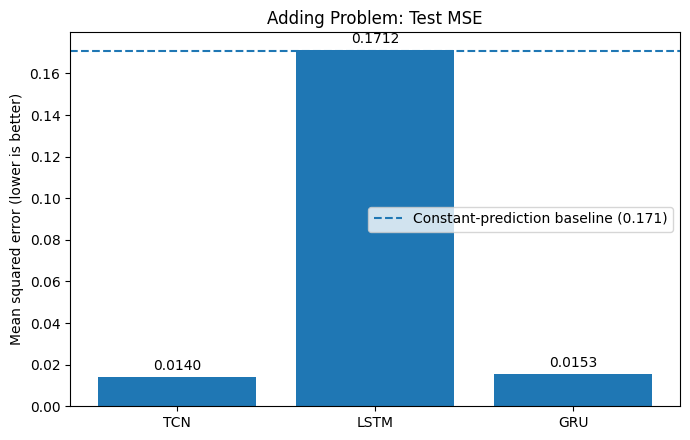

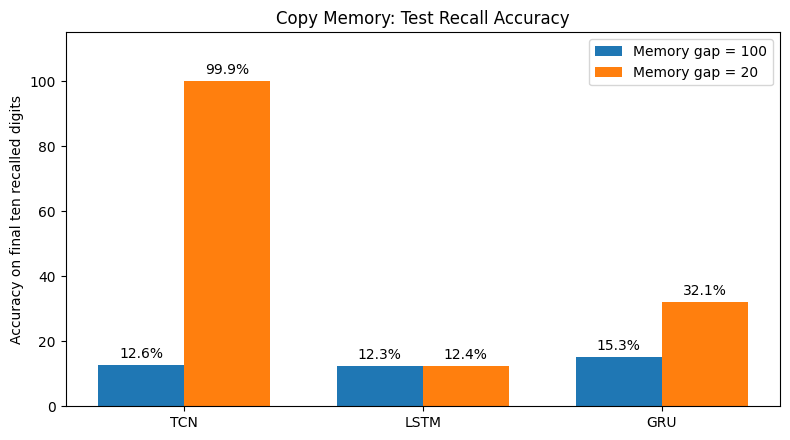

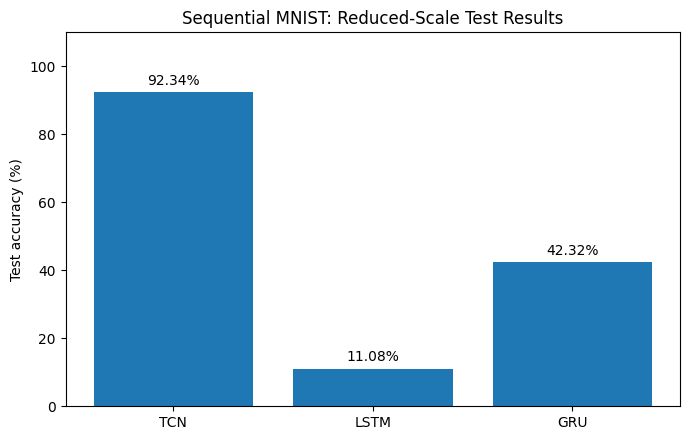

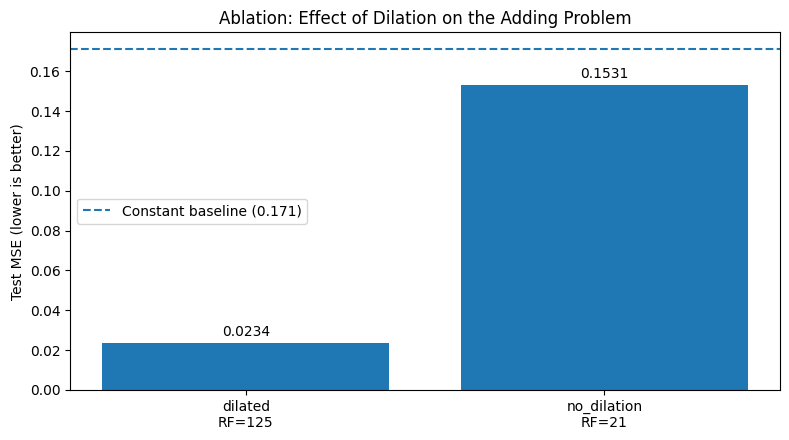

All plots and the consolidated result table have been saved.
Summary CSV: /content/drive/MyDrive/DL_TCN_Project/results/final_results_summary.csv
Plots folder: /content/drive/MyDrive/DL_TCN_Project/results/plots


,task,configuration,model,metric,value,notes
0,Adding Problem,sequence length 100,TCN,test MSE,0.013991,constant baseline MSE=0.17104
1,Adding Problem,sequence length 100,LSTM,test MSE,0.171229,constant baseline MSE=0.17104
2,Adding Problem,sequence length 100,GRU,test MSE,0.015329,constant baseline MSE=0.17104
3,Copy Memory,memory gap 100; total length 120,TCN,test recall accuracy,0.126172,longer-gap run; poor recall for all models
4,Copy Memory,memory gap 100; total length 120,LSTM,test recall accuracy,0.123486,longer-gap run; poor recall for all models
5,Copy Memory,memory gap 100; total length 120,GRU,test recall accuracy,0.152539,longer-gap run; poor recall for all models
6,Copy Memory,memory gap 20; total length 40,TCN,test digit accuracy,0.999414,exact sequence accuracy=0.99414
7,Copy Memory,memory gap 20; total length 40,LSTM,test digit accuracy,0.124219,exact sequence accuracy=0.00000
8,Copy Memory,memory gap 20; total length 40,GRU,test digit accuracy,0.321289,exact sequence accuracy=0.00000
9,Sequential MNIST,"train=12000, validation=2000, test=5000, epochs=8",TCN,test accuracy,0.923400,test loss=0.26328


In [2]:
# Step 26: Consolidate completed results and generate report plots.
# This cell reads saved CSVs only. It does not rerun training.

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

# Reconnect Drive only if necessary.
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DL_TCN_Project")
RESULTS_DIR = PROJECT_DIR / "results"
PLOTS_DIR = RESULTS_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Load the five completed experiment tables.
adding = pd.read_csv(RESULTS_DIR / "adding_comparison.csv")
copy_long = pd.read_csv(RESULTS_DIR / "copy_comparison_v2.csv")
copy_short = pd.read_csv(RESULTS_DIR / "copy_comparison_v3.csv")
mnist = pd.read_csv(RESULTS_DIR / "seq_mnist_comparison.csv")
ablation = pd.read_csv(RESULTS_DIR / "adding_dilation_ablation.csv")

# --------------------------------------------------
# Plot 1: Adding Problem
# --------------------------------------------------

baseline = adding["constant_baseline_test_mse"].iloc[0]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(adding["model"], adding["test_mse"])

ax.axhline(
    baseline,
    linestyle="--",
    label=f"Constant-prediction baseline ({baseline:.3f})",
)

ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_title("Adding Problem: Test MSE")
ax.set_ylabel("Mean squared error (lower is better)")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "adding_problem_mse.png", dpi=200)
plt.show()
plt.close(fig)

# --------------------------------------------------
# Plot 2: Copy Memory at two different memory gaps
# --------------------------------------------------

models_order = ["TCN", "LSTM", "GRU"]
long_values = (
    copy_long.set_index("model")
    .reindex(models_order)["test_recall_accuracy"]
    .to_numpy() * 100
)
short_values = (
    copy_short.set_index("model")
    .reindex(models_order)["test_digit_accuracy"]
    .to_numpy() * 100
)

x = range(len(models_order))
width = 0.36

fig, ax = plt.subplots(figsize=(8, 4.5))
bars_long = ax.bar(
    [i - width / 2 for i in x],
    long_values,
    width,
    label="Memory gap = 100",
)
bars_short = ax.bar(
    [i + width / 2 for i in x],
    short_values,
    width,
    label="Memory gap = 20",
)

ax.bar_label(bars_long, fmt="%.1f%%", padding=3)
ax.bar_label(bars_short, fmt="%.1f%%", padding=3)
ax.set_xticks(list(x), models_order)
ax.set_ylabel("Accuracy on final ten recalled digits")
ax.set_title("Copy Memory: Test Recall Accuracy")
ax.set_ylim(0, 115)
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "copy_memory_accuracy.png", dpi=200)
plt.show()
plt.close(fig)

# --------------------------------------------------
# Plot 3: Sequential MNIST
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(mnist["model"], mnist["test_accuracy"] * 100)

ax.bar_label(bars, fmt="%.2f%%", padding=3)
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Sequential MNIST: Reduced-Scale Test Results")
ax.set_ylim(0, 110)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "sequential_mnist_accuracy.png", dpi=200)
plt.show()
plt.close(fig)

# --------------------------------------------------
# Plot 4: Dilation ablation
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [
    f"{row['model'].replace('adding_ablation_', '')}\n"
    f"RF={int(row['receptive_field'])}"
    for _, row in ablation.iterrows()
]
bars = ax.bar(labels, ablation["test_mse"])

ablation_baseline = ablation["constant_baseline_test_mse"].iloc[0]
ax.axhline(
    ablation_baseline,
    linestyle="--",
    label=f"Constant baseline ({ablation_baseline:.3f})",
)

ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_ylabel("Test MSE (lower is better)")
ax.set_title("Ablation: Effect of Dilation on the Adding Problem")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "dilation_ablation.png", dpi=200)
plt.show()
plt.close(fig)

# --------------------------------------------------
# Build one consolidated table from actual results.
# Different metrics remain explicitly labelled.
# --------------------------------------------------

summary_rows = []

for _, row in adding.iterrows():
    summary_rows.append({
        "task": "Adding Problem",
        "configuration": "sequence length 100",
        "model": row["model"],
        "metric": "test MSE",
        "value": row["test_mse"],
        "notes": f"constant baseline MSE={baseline:.5f}",
    })

for _, row in copy_long.iterrows():
    summary_rows.append({
        "task": "Copy Memory",
        "configuration": "memory gap 100; total length 120",
        "model": row["model"],
        "metric": "test recall accuracy",
        "value": row["test_recall_accuracy"],
        "notes": "longer-gap run; poor recall for all models",
    })

for _, row in copy_short.iterrows():
    summary_rows.append({
        "task": "Copy Memory",
        "configuration": "memory gap 20; total length 40",
        "model": row["model"],
        "metric": "test digit accuracy",
        "value": row["test_digit_accuracy"],
        "notes": (
            f"exact sequence accuracy="
            f"{row['test_exact_sequence_accuracy']:.5f}"
        ),
    })

for _, row in mnist.iterrows():
    summary_rows.append({
        "task": "Sequential MNIST",
        "configuration": (
            f"train={row['train_samples']}, "
            f"validation={row['validation_samples']}, "
            f"test={row['test_samples']}, "
            f"epochs={row['epochs_completed']}"
        ),
        "model": row["model"],
        "metric": "test accuracy",
        "value": row["test_accuracy"],
        "notes": f"test loss={row['test_loss']:.5f}",
    })

for _, row in ablation.iterrows():
    summary_rows.append({
        "task": "Adding Problem ablation",
        "configuration": (
            f"dilation={row['dilation']}; "
            f"receptive field={row['receptive_field']}"
        ),
        "model": row["model"],
        "metric": "test MSE",
        "value": row["test_mse"],
        "notes": f"constant baseline MSE={row['constant_baseline_test_mse']:.5f}",
    })

summary = pd.DataFrame(summary_rows)
summary_path = RESULTS_DIR / "final_results_summary.csv"
summary.to_csv(summary_path, index=False)

print("All plots and the consolidated result table have been saved.")
print(f"Summary CSV: {summary_path}")
print(f"Plots folder: {PLOTS_DIR}")

display(summary)

In [3]:
# Step 27: Compare paper-reported results with our experiments.
# Source: Bai, Kolter and Koltun (2018), Table 1.
# All our results are loaded from previously saved CSV files.

from pathlib import Path
import pandas as pd
from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DL_TCN_Project")
RESULTS_DIR = PROJECT_DIR / "results"

adding = pd.read_csv(RESULTS_DIR / "adding_comparison.csv")
copy_long = pd.read_csv(RESULTS_DIR / "copy_comparison_v2.csv")
copy_short = pd.read_csv(RESULTS_DIR / "copy_comparison_v3.csv")
mnist = pd.read_csv(RESULTS_DIR / "seq_mnist_comparison.csv")
ablation = pd.read_csv(RESULTS_DIR / "adding_dilation_ablation.csv")

# Values reported in Table 1 of the 2018 paper.
paper_adding = {"TCN": 5.8e-5, "LSTM": 0.164, "GRU": 5.3e-5}
paper_copy = {"TCN": 3.5e-5, "LSTM": 0.0204, "GRU": 0.0197}
paper_mnist = {"TCN": 99.0, "LSTM": 87.2, "GRU": 96.2}

rows = []

# Adding Problem: the loss metric is comparable, but settings differ.
for _, r in adding.iterrows():
    model = r["model"]
    rows.append({
        "task": "Adding Problem",
        "model": model,
        "paper_setting": "T=600",
        "paper_metric": "loss / MSE",
        "paper_value": paper_adding[model],
        "our_setting": "sequence length 100; 4096 train, 1024 validation, 2048 test; 20 epochs",
        "our_metric": "test MSE",
        "our_value": r["test_mse"],
        "comparison_note": "Same task; reduced sequence length and different training configuration.",
    })

# Copy Memory: the paper reports loss, while our saved runs report recall accuracy.
for _, r in copy_long.iterrows():
    model = r["model"]
    rows.append({
        "task": "Copy Memory",
        "model": model,
        "paper_setting": "T=1000; total sequence length 1020",
        "paper_metric": "loss",
        "paper_value": paper_copy[model],
        "our_setting": "memory gap 100; total sequence length 120",
        "our_metric": "test recall accuracy (%)",
        "our_value": 100 * r["test_recall_accuracy"],
        "comparison_note": "Different sequence length and metric; numeric values are not directly comparable.",
    })

# Shorter Copy Memory diagnostic: no direct counterpart in Table 1.
for _, r in copy_short.iterrows():
    model = r["model"]
    rows.append({
        "task": "Copy Memory diagnostic",
        "model": model,
        "paper_setting": "Paper benchmark: T=1000",
        "paper_metric": "loss",
        "paper_value": paper_copy[model],
        "our_setting": "memory gap 20; total sequence length 40",
        "our_metric": "test digit accuracy (%)",
        "our_value": 100 * r["test_digit_accuracy"],
        "comparison_note": "Short-gap diagnostic; not a reproduction of the paper's long-memory benchmark.",
    })

# Sequential MNIST: both report accuracy, but training budgets differ.
for _, r in mnist.iterrows():
    model = r["model"]
    rows.append({
        "task": "Sequential MNIST",
        "model": model,
        "paper_setting": "Paper Table 1; approximately 70K parameters",
        "paper_metric": "accuracy (%)",
        "paper_value": paper_mnist[model],
        "our_setting": (
            f"{int(r['train_samples'])} train, "
            f"{int(r['validation_samples'])} validation, "
            f"{int(r['test_samples'])} test; "
            f"{int(r['epochs_completed'])} epochs; "
            f"{int(r['parameters']):,} parameters"
        ),
        "our_metric": "test accuracy (%)",
        "our_value": 100 * r["test_accuracy"],
        "comparison_note": "Same task and metric; reduced data, model size and training budget.",
    })

# Our ablation is a custom experiment, not a paper-table reproduction.
for _, r in ablation.iterrows():
    rows.append({
        "task": "Adding Problem ablation",
        "model": r["model"],
        "paper_setting": "No directly corresponding result in Table 1",
        "paper_metric": "N/A",
        "paper_value": None,
        "our_setting": f"receptive field {int(r['receptive_field'])}",
        "our_metric": "test MSE",
        "our_value": r["test_mse"],
        "comparison_note": "Our controlled dilation experiment; constant-prediction baseline is reported separately.",
    })

comparison = pd.DataFrame(rows)

output_path = RESULTS_DIR / "paper_vs_our_results.csv"
comparison.to_csv(output_path, index=False)

print("Paper comparison saved successfully.")
print(f"File: {output_path}")

display(comparison)

Paper comparison saved successfully.
File: /content/drive/MyDrive/DL_TCN_Project/results/paper_vs_our_results.csv


,task,model,paper_setting,paper_metric,paper_value,our_setting,our_metric,our_value,comparison_note
0,Adding Problem,TCN,T=600,loss / MSE,0.000058,"sequence length 100; 4096 train, 1024 validati...",test MSE,0.013991,Same task; reduced sequence length and differe...
1,Adding Problem,LSTM,T=600,loss / MSE,0.164000,"sequence length 100; 4096 train, 1024 validati...",test MSE,0.171229,Same task; reduced sequence length and differe...
2,Adding Problem,GRU,T=600,loss / MSE,0.000053,"sequence length 100; 4096 train, 1024 validati...",test MSE,0.015329,Same task; reduced sequence length and differe...
3,Copy Memory,TCN,T=1000; total sequence length 1020,loss,0.000035,memory gap 100; total sequence length 120,test recall accuracy (%),12.617187,Different sequence length and metric; numeric ...
4,Copy Memory,LSTM,T=1000; total sequence length 1020,loss,0.020400,memory gap 100; total sequence length 120,test recall accuracy (%),12.348633,Different sequence length and metric; numeric ...
5,Copy Memory,GRU,T=1000; total sequence length 1020,loss,0.019700,memory gap 100; total sequence length 120,test recall accuracy (%),15.253906,Different sequence length and metric; numeric ...
6,Copy Memory diagnostic,TCN,Paper benchmark: T=1000,loss,0.000035,memory gap 20; total sequence length 40,test digit accuracy (%),99.941406,Short-gap diagnostic; not a reproduction of th...
7,Copy Memory diagnostic,LSTM,Paper benchmark: T=1000,loss,0.020400,memory gap 20; total sequence length 40,test digit accuracy (%),12.421875,Short-gap diagnostic; not a reproduction of th...
8,Copy Memory diagnostic,GRU,Paper benchmark: T=1000,loss,0.019700,memory gap 20; total sequence length 40,test digit accuracy (%),32.128906,Short-gap diagnostic; not a reproduction of th...
9,Sequential MNIST,TCN,Paper Table 1; approximately 70K parameters,accuracy (%),99.000000,"12000 train, 2000 validation, 5000 test; 8 epo...",test accuracy (%),92.340000,"Same task and metric; reduced data, model size..."
